<a href="https://colab.research.google.com/github/fergogu27-ctrl/EDPII/blob/main/Modelo_SIR_con_pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ajuste de parámetros del modelo SIR con MCMC y PyMC


- Usar MCMC con el algoritmo de Metropolis-Hastings para buscar los parámetros $a$ y $b$ que minimizan el error del modelo SIR.
- Replantear el problema desde un enfoque bayesiano usando PyMC.

 Al inicio se incluyen los datos, el modelo SIR y la función de error $\chi^2(a,b)$ construidos anteriormente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp   #permite resolver numéricamente el sistema de ecuaciones diferenciales del modelo SIR.

In [2]:
t_datos = np.arange(0, 15)

I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237, 191,
    125, 69, 27, 11, 4
])

N = 763

##  Graficar los datos

Antes de ajustar el modelo conviene observar la forma de los datos.  
Esta gráfica permite identificar que el número de infectados aumenta, alcanza un máximo y después disminuye.

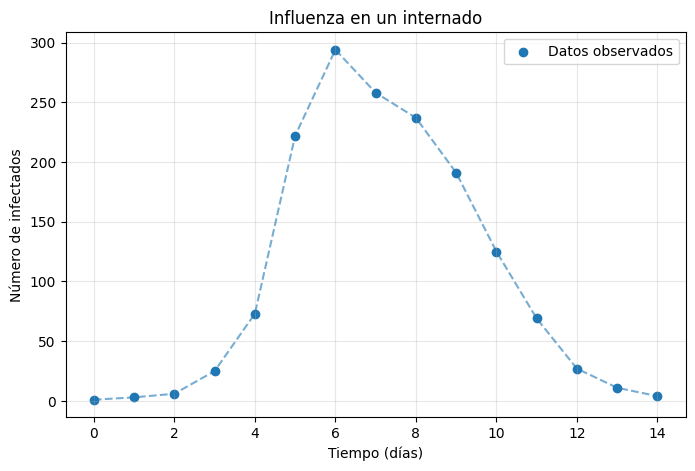

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(t_datos, I_datos, label="Datos observados")
plt.plot(t_datos, I_datos, "--", alpha=0.6)

plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")
plt.title("Influenza en un internado")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. Definir el modelo SIR

El modelo SIR divide la población en tres grupos:

- $S(t)$: susceptibles,
- $I(t)$: infectados,
- $R(t)$: removidos o recuperados.

Las ecuaciones son
$$\frac{dS}{dt}=-aSI,$$
$$\frac{dI}{dt}=aSI-bI,$$
$$\frac{dR}{dt}=bI.$$

Los parámetros $a$ y $b$ se mantienen libres porque posteriormente serán estimados.

In [4]:
def modelo_SIR(t, y, a, b):
    S, I, R = y

    dSdt = -a*S*I
    dIdt = a*S*I - b*I
    dRdt = b*I

    return [dSdt, dIdt, dRdt]

## Definir las condiciones iniciales

La población total es de 763 personas.

Al inicio hay un infectado y ningún recuperado, por lo que:

$$I(0)=1,\qquad R(0)=0,$$

y por conservación de población,

$$S(0)=763-1=762.$$

In [5]:
S0 = 762
I0 = 1
R0 = 0

y0 = [S0, I0, R0]

## Crear una función que resuelva el modelo SIR

Esta función recibe cualquier par de parámetros $(a,b)$, resuelve numéricamente las ecuaciones diferenciales y devuelve las trayectorias $S(t)$, $I(t)$ y $R(t)$.

Esto será indispensable porque el algoritmo MCMC evaluará muchos pares diferentes de parámetros.

In [6]:
def resolver_SIR(a, b):

    solucion = solve_ivp(
        fun=lambda t, y: modelo_SIR(t, y, a, b),
        t_span=(0, 14),
        y0=y0,
        t_eval=t_datos,
        method="RK45"
    )

    S = solucion.y[0]
    I = solucion.y[1]
    R = solucion.y[2]

    return S, I, R

## 7. Definir la función de error $\chi^2(a,b)$

Para cada par $(a,b)$, resolvemos el modelo SIR y comparamos los infectados predichos con los datos observados.

Usaremos
$$\chi^2(a,b)
=
\sum_i
\left[
I_{\text{modelo}}(t_i;a,b)-I_i^{\text{obs}}
\right]^2.$$

El mejor ajuste corresponderá a valores de $a$ y $b$ que hagan pequeño este error.

In [7]:
def chi_cuadrada(a, b):

    S, I_modelo, R = resolver_SIR(a, b)

    chi2 = np.sum((I_modelo - I_datos)**2)

    return chi2

#  MCMC con Metropolis-Hastings

La idea es recorrer el espacio de parámetros $(a,b)$ mediante una cadena de Markov.

Para utilizar Metropolis-Hastings definimos una función objetivo proporcional a
$$\pi(a,b)\propto
\exp\left(-\frac{\chi^2(a,b)}{2T}\right).$$

De esta manera, los valores con menor $\chi^2$ tienen mayor probabilidad de ser aceptados.

Si el candidato es mejor que el estado actual, se acepta automáticamente. Si es peor, todavía puede aceptarse con cierta probabilidad.

## Implementar Metropolis-Hastings

En este bloque se construye el algoritmo.

En cada iteración:

1. Se propone un nuevo valor de $a$ y de $b$ usando distribuciones normales centradas en los valores actuales.
2. Se calcula el nuevo $\chi^2$.
3. Se calcula la probabilidad de aceptación.
4. Se decide aleatoriamente si se acepta o rechaza el nuevo punto.
5. Se guarda el estado de la cadena.

El parámetro $T$ controla qué tan fácil es aceptar propuestas peores y, por tanto, ayuda a que la cadena explore el espacio.

In [8]:
def metropolis_hastings(
    n_iter=25000,
    a0=0.002,
    b0=0.40,
    sigma_a=6e-5,
    sigma_b=0.025,
    T=400,
    seed=456
):

    rng = np.random.default_rng(seed)

    cadena = np.zeros((n_iter, 2))
    valores_chi2 = np.zeros(n_iter)

    a_actual = a0
    b_actual = b0

    chi2_actual = chi_cuadrada(a_actual, b_actual)

    aceptados = 0

    for i in range(n_iter):

        # Proponer un nuevo punto
        a_propuesto = rng.normal(a_actual, sigma_a)
        b_propuesto = rng.normal(b_actual, sigma_b)

        # Restringir los parámetros a valores físicamente razonables
        if (a_propuesto <= 0 or a_propuesto >= 0.01 or
            b_propuesto <= 0 or b_propuesto >= 1):

            cadena[i] = [a_actual, b_actual]
            valores_chi2[i] = chi2_actual
            continue

        # Evaluar el error del candidato
        chi2_propuesto = chi_cuadrada(a_propuesto, b_propuesto)

        # Probabilidad de aceptación en escala logarítmica
        log_alpha = -(chi2_propuesto - chi2_actual)/(2*T)

        # Regla de aceptación
        if np.log(rng.random()) < min(0, log_alpha):

            a_actual = a_propuesto
            b_actual = b_propuesto
            chi2_actual = chi2_propuesto

            aceptados += 1

        cadena[i] = [a_actual, b_actual]
        valores_chi2[i] = chi2_actual

    tasa_aceptacion = aceptados/n_iter

    return cadena, valores_chi2, tasa_aceptacion

In [9]:
cadena, chi2_cadena, tasa = metropolis_hastings()

print("Tasa de aceptación:", tasa)

Tasa de aceptación: 0.35824


## Encontrar el mejor par de parámetros

Una vez construida la cadena, buscamos el punto con el menor valor de $\chi^2$.

Ese punto representa el mejor ajuste encontrado por el algoritmo.

In [10]:
indice_mejor = np.argmin(chi2_cadena)

a_mejor = cadena[indice_mejor, 0]
b_mejor = cadena[indice_mejor, 1]
chi2_min = chi2_cadena[indice_mejor]

print("a =", a_mejor)
print("b =", b_mejor)
print("chi² mínimo =", chi2_min)

a = 0.0021798582456276517
b = 0.4456259577781815
chi² mínimo = 4446.787983389339


## Graficar la cadena del parámetro $a$

Esta gráfica permite observar cómo evoluciona el parámetro $a$ a lo largo de las iteraciones.

Si la cadena explora de manera estable una región y deja de mostrar tendencias sistemáticas, es una señal favorable de convergencia.

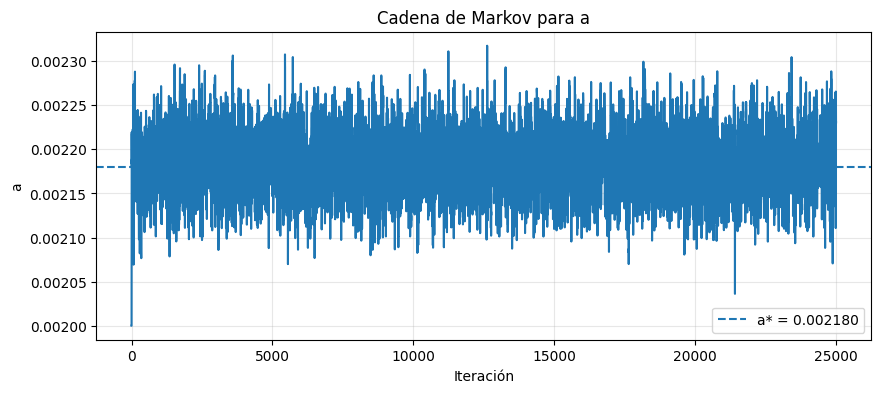

In [11]:
plt.figure(figsize=(10, 4))

plt.plot(cadena[:, 0])

plt.axhline(
    a_mejor,
    linestyle="--",
    label=f"a* = {a_mejor:.6f}"
)

plt.xlabel("Iteración")
plt.ylabel("a")
plt.title("Cadena de Markov para a")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##  Graficar la cadena del parámetro $b$

Se realiza el mismo análisis para el parámetro $b$.

Esto ayuda a verificar visualmente que el algoritmo no permanece atrapado en un único punto.

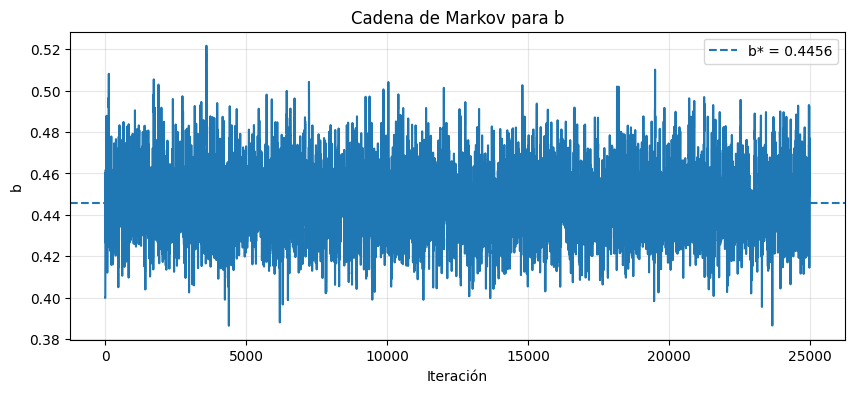

In [12]:
plt.figure(figsize=(10, 4))

plt.plot(cadena[:, 1])

plt.axhline(
    b_mejor,
    linestyle="--",
    label=f"b* = {b_mejor:.4f}"
)

plt.xlabel("Iteración")
plt.ylabel("b")
plt.title("Cadena de Markov para b")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##  Visualizar el espacio de parámetros

Aquí graficamos simultáneamente los valores de $a$ y $b$ visitados por la cadena.

Se descartan las primeras 5000 iteraciones como **burn-in**, ya que corresponden a la etapa inicial de adaptación de la cadena.

La nube de puntos muestra qué región del espacio de parámetros es explorada con mayor frecuencia.

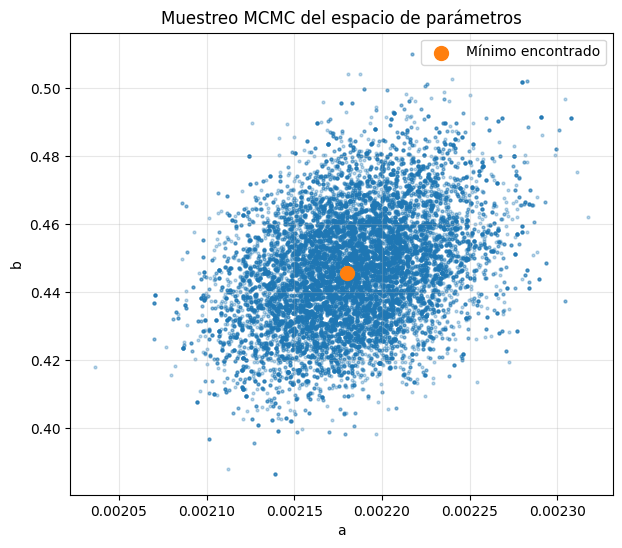

In [13]:
burn = 5000

plt.figure(figsize=(7, 6))

plt.scatter(
    cadena[burn:, 0],
    cadena[burn:, 1],
    s=4,
    alpha=0.3
)

plt.scatter(
    a_mejor,
    b_mejor,
    s=100,
    label="Mínimo encontrado"
)

plt.xlabel("a")
plt.ylabel("b")
plt.title("Muestreo MCMC del espacio de parámetros")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Comparar el mejor modelo SIR con los datos

Usamos los mejores parámetros encontrados para resolver nuevamente el modelo.

Después se compara la curva de infectados predicha con los datos observados.

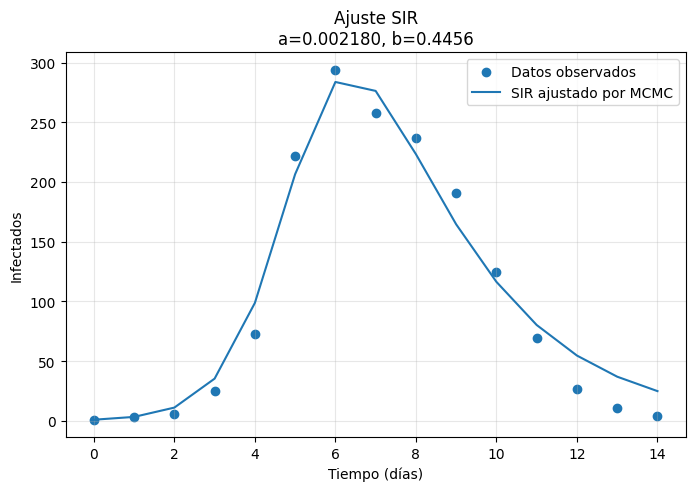

In [14]:
S_mejor, I_mejor, R_mejor = resolver_SIR(
    a_mejor,
    b_mejor
)

plt.figure(figsize=(8, 5))

plt.scatter(
    t_datos,
    I_datos,
    label="Datos observados"
)

plt.plot(
    t_datos,
    I_mejor,
    label="SIR ajustado por MCMC"
)

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados")

plt.title(
    f"Ajuste SIR\n"
    f"a={a_mejor:.6f}, b={b_mejor:.4f}"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

#  Enfoque bayesiano con PyMC

En este punto el objetivo ya no es solamente encontrar un único par $(a,b)$, sino describir la incertidumbre sobre dichos parámetros.

Buscamos la distribución posterior

$$p(a,b,\sigma\mid D)
\propto
p(D\mid a,b,\sigma)\,p(a)\,p(b)\,p(\sigma).$$

La distribución posterior combina:

- información previa sobre los parámetros,
- el modelo SIR,
- los datos observados.

In [15]:
!pip install -q pymc pytensor arviz     #visualizar cadenas posteriores

## Bibliotecas para el análisis bayesiano

PyMC construye el modelo probabilístico, ArviZ facilita el diagnóstico y las gráficas, y PyTensor permite integrar funciones externas en el modelo.

In [16]:
import pymc as pm
import arviz as az

import pytensor.tensor as pt
from pytensor.compile.ops import as_op

##  Construir la log-verosimilitud del modelo SIR

Supondremos que los datos observados se distribuyen normalmente alrededor de la predicción del modelo:

$$I_i^{obs}
\sim
N\left(I_{\text{SIR}}(t_i;a,b),\sigma\right).$$

La función siguiente:

1. recibe $a$, $b$ y $\sigma$,
2. resuelve el modelo SIR,
3. calcula los residuos,
4. devuelve el logaritmo de la verosimilitud.


In [17]:
@as_op(
    itypes=[pt.dscalar, pt.dscalar, pt.dscalar],
    otypes=[pt.dscalar]
)
def loglike_SIR(a, b, sigma):

    a = float(a)
    b = float(b)
    sigma = float(sigma)

    S, I_modelo, R = resolver_SIR(a, b)

    residuos = I_datos - I_modelo

    n = len(I_datos)

    logL = (
        -n*np.log(sigma)
        -0.5*np.sum((residuos/sigma)**2)
    )

    return np.array(logL, dtype=np.float64)

/tmp/ipykernel_1090/3898922916.py:1: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @as_op(


## Construir el modelo bayesiano en PyMC

Aquí se especifican las distribuciones previas:

$$a\sim U(0,0.01),$$
$$b\sim U(0,1),$$
$$\sigma\sim \text{HalfNormal}(50).$$

Después se incorpora la log-verosimilitud del modelo SIR mediante `pm.Potential`.

Finalmente se utiliza el algoritmo `pm.Metropolis()` para generar las cadenas MCMC.

Se ejecutan cuatro cadenas independientes para facilitar el diagnóstico de convergencia.

In [18]:
with pm.Model() as modelo_SIR_bayesiano:

    a = pm.Uniform(
        "a",
        lower=0.0,
        upper=0.01,
        initval=0.00218
    )

    b = pm.Uniform(
        "b",
        lower=0.0,
        upper=1.0,
        initval=0.445
    )

    sigma = pm.HalfNormal(
        "sigma",
        sigma=50.0,
        initval=20.0
    )

    pm.Potential(
        "likelihood",
        loglike_SIR(a, b, sigma)
    )

    step = pm.Metropolis()

    idata = pm.sample(
        draws=15000,
        tune=5000,
        chains=4,
        cores=1,
        step=step,
        random_seed=123,
        return_inferencedata=True
    )

Output()

##  Obtener un resumen de las distribuciones posteriores

`az.summary` calcula estadísticas importantes de cada parámetro, por ejemplo:

- media posterior,
- desviación estándar,
- intervalos de credibilidad,
- medidas de diagnóstico de las cadenas.

Esto permite cuantificar la incertidumbre de $a$, $b$ y $\sigma$.

In [19]:
az.summary(
    idata,
    var_names=["a", "b", "sigma"],
    hdi_prob=0.95
)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002,0.000,0.002,0.002,0.000,0.000,8806.0,9798.0,1.0
b,0.447,0.017,0.413,0.481,0.000,0.000,8514.0,10776.0,1.0
sigma,20.355,4.515,12.490,29.070,0.051,0.054,8488.0,9882.0,1.0


## Graficar las cadenas y distribuciones posteriores

Las gráficas muestran, para cada parámetro:

- la trayectoria de las cadenas,
- la distribución posterior estimada.

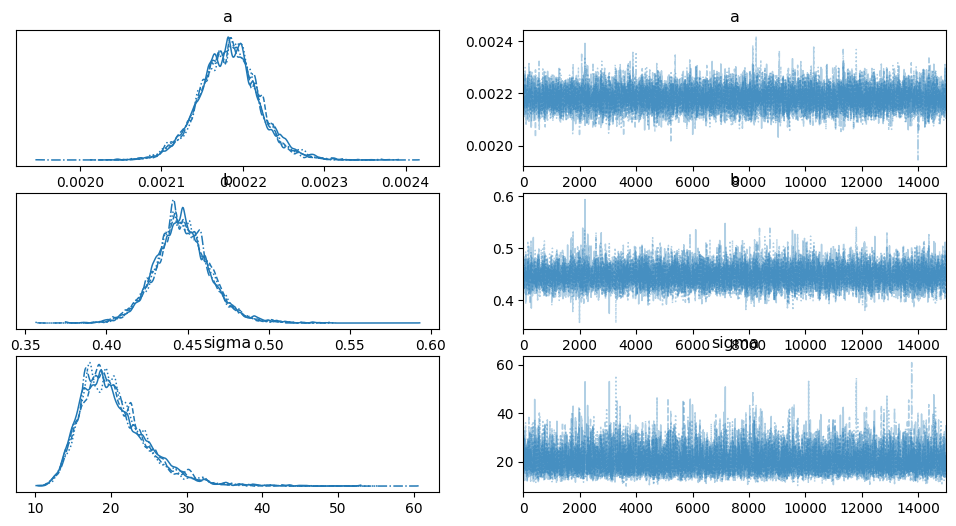

In [20]:
az.plot_trace(
    idata,
    var_names=["a", "b", "sigma"]
);

## Graficar la distribución conjunta de $a$ y $b$

Esta gráfica permite observar la relación entre ambos parámetros.

La concentración de la distribución indica las combinaciones de $a$ y $b$ más compatibles con los datos.

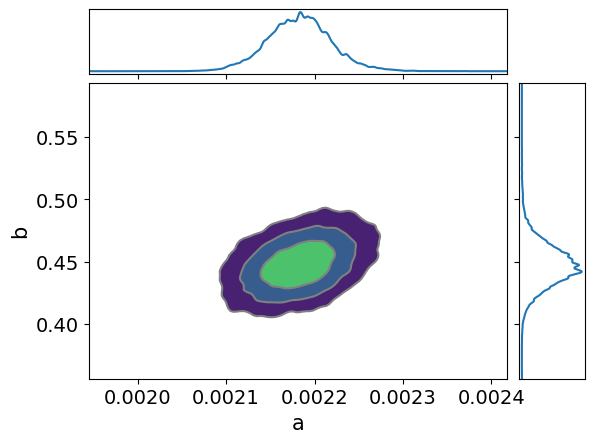

In [21]:
az.plot_pair(
    idata,
    var_names=["a", "b"],
    kind="kde",
    marginals=True
);

## Calcular los valores medios posteriores

En lugar de utilizar solamente el punto que minimiza $\chi^2$, ahora calculamos las medias de las distribuciones posteriores de $a$ y $b$.

Estas medias representan valores característicos de los parámetros después de incorporar los datos mediante el enfoque bayesiano.

In [22]:
posterior = idata.posterior

a_post = float(posterior["a"].mean())
b_post = float(posterior["b"].mean())

print("Media posterior de a:", a_post)
print("Media posterior de b:", b_post)

Media posterior de a: 0.002183105654504821
Media posterior de b: 0.44708573680001895


## Graficar el SIR usando las medias posteriores

Finalmente resolvemos el modelo SIR utilizando las medias posteriores de $a$ y $b$.

La curva obtenida se compara con los datos para visualizar el ajuste bayesiano.

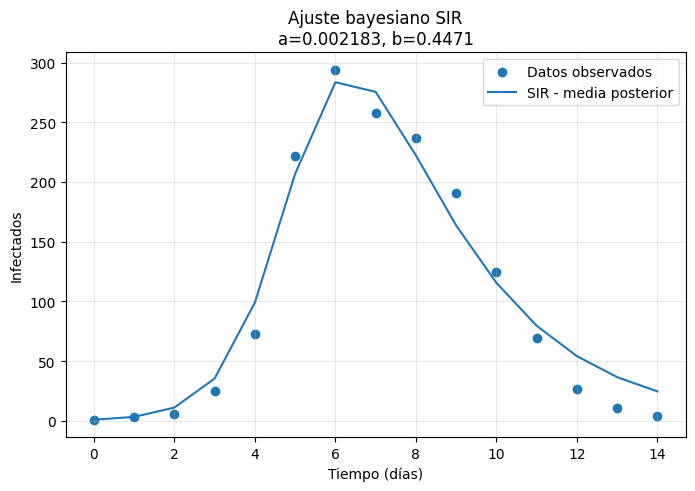

In [23]:
S_post, I_post, R_post = resolver_SIR(
    a_post,
    b_post
)

plt.figure(figsize=(8, 5))

plt.scatter(
    t_datos,
    I_datos,
    label="Datos observados"
)

plt.plot(
    t_datos,
    I_post,
    label="SIR - media posterior"
)

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados")

plt.title(
    f"Ajuste bayesiano SIR\n"
    f"a={a_post:.6f}, b={b_post:.4f}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Conclusión

El procedimiento completo sigue la secuencia:

$$\text{Datos}
\longrightarrow
\text{Modelo SIR}
\longrightarrow
\chi^2(a,b)
\longrightarrow
\text{Metropolis-Hastings}$$

para encontrar la región de parámetros con menor error.

Posteriormente, el enfoque bayesiano amplía el análisis:

$$\text{Priors}
+
\text{Modelo SIR}
+
\text{Datos}
\longrightarrow
p(a,b,\sigma\mid D).$$

Así, además de obtener valores adecuados para $a$ y $b$, podemos estudiar la incertidumbre asociada a su estimación.